# Dynamic tariffs for EV charging in Shenzhen
**Question.** Can we forecast how busy each station will be next hour, and what gross revenue would an occupancy-based tariff imply versus ₹15/kWh? We process every station file and score only hours with valid observations.

**Workflow** · Read and validate five-minute observations → construct station-hour features → compare demand forecasts → monitor past forecast errors → quote a one-hour tariff → replay revenue under explicit demand assumptions.

Only three agents appear here: a demand forecaster, a tariff rule and a daily monitoring selector. This is an offline chronological evaluation. A tariff applies to energy in a clock hour; session-level billing would require session records.

## 1 · Configuration and reproducibility
Place the inner UrbanEVDataset.zip next to the notebook or set URBANEV_ZIP. Times are local to Shenzhen. The source is [UrbanEV on Dryad](https://doi.org/10.5061/dryad.np5hqc04z). Published energy volume is an estimate in kWh. INR tariffs are hypothetical, independent of historical Chinese prices.

In [1]:
from pathlib import Path
import os
import matplotlib.pyplot as plt
from zipfile import ZipFile

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from threadpoolctl import threadpool_limits

OUT = Path("results")
OUT.mkdir(exist_ok=True)
GRID = pd.date_range("2022-09-01", "2023-03-01", freq="5min", inclusive="left")
HOURS = GRID[::12]
BASE = ["plugs", "fast_fraction", "hour", "weekday", "occ", "energy"]
LAST = ["end_occ", "change15", "energy15"]
LAGS = [f"{col}_{lag}" for col in ["occ", "energy"] for lag in [1, 2, 23, 167]]
TARGETS = {"occ": "next_occ", "energy": "next_energy"}



ARCHIVE = Path(os.environ.get("URBANEV_ZIP", "UrbanEVDataset.zip"))
if not ARCHIVE.is_file():
    raise FileNotFoundError("Place the inner UrbanEVDataset.zip beside this notebook or set URBANEV_ZIP.")

## 2 · Build one example per station and target hour
Remove duplicate timestamp groups and restore the regular 5-minute grid. Counts must be nonnegative and busy + idle must equal installed capacity. Average 12 occupancy fractions and sum 12 interval energy values; gaps propagate rather than becoming zero. A scored example needs complete input and outcome hours.

Forecast at the boundary: the completed 09:00–10:00 hour can inform a quote for 10:00–11:00. Hour and weekday belong to the target. Lags 23 and 167 from the completed hour align with the target time yesterday and last week. The enhanced features add final occupancy, its change over 15 minutes and recent energy. Station capacity and fast-plug share describe sites without treating their IDs as numbers.

In [2]:
def station_frame(zipfile, path, site, meta):
    raw = pd.read_csv(zipfile.open(path), usecols=["time", "busy", "idle", "volume"])
    raw["time"] = pd.to_datetime(raw.time)
    raw = raw[~raw.time.duplicated(keep=False)].set_index("time").reindex(GRID)
    plugs = meta.charge_count
    valid = (raw.busy >= 0) & (raw.idle >= 0) & (raw.busy + raw.idle == plugs)
    occ = (raw.busy.where(valid) / plugs).to_numpy().reshape(-1, 12)
    energy = raw.volume.where(raw.volume >= 0).to_numpy().reshape(-1, 12)
    t = HOURS + pd.Timedelta(hours=1)
    frame = pd.DataFrame(dict(site=site, slot=np.arange(len(t))+1, plugs=plugs,
                              fast_fraction=meta.fast_count/plugs if plugs else np.nan,
                              hour=t.hour, weekday=t.weekday, occ=occ.mean(axis=1),
                              energy=energy.sum(axis=1), end_occ=occ[:, -1],
                              change15=occ[:, -1]-occ[:, -4], energy15=energy[:, -3:].sum(axis=1)))
    for col, target in TARGETS.items():
        frame[target] = frame[col].shift(-1)
        for lag in [1, 2, 23, 167]:
            frame[f"{col}_{lag}"] = frame[col].shift(lag)
    return frame.dropna(subset=["occ","energy",*TARGETS.values()]).astype("float32")

### Read the entire network
Discover all station files in the raw archive. Keep an audit row even for stations that provide zero eligible pairs. The test counts show how far the results extend across the network.

In [3]:
def prepare(archive):
    frames = []
    with ZipFile(archive) as z:
        paths = sorted(p for p in z.namelist() if "/station-raw/" in p or "_station-raw/" in p)
        sites = [p for p in paths if "/charge_5min/" in p and p.endswith(".csv")]
        meta = pd.read_csv(z.open(next(p for p in paths if p.endswith("/station_information.csv")))).set_index("station_id")
        assert sites and len(sites) == len({Path(p).stem for p in sites})
        for path in sites:
            site = int(Path(path).stem)
            frame = station_frame(z, path, site, meta.loc[site])
            frames.append(frame)
        audit = pd.DataFrame({"site":[int(Path(p).stem) for p in sites], "valid_pairs":[len(f) for f in frames],
                              "feb_pairs":[(f.slot >= (pd.Timestamp("2023-02-01")-HOURS[0]).days*24).sum() for f in frames]})
        audit.to_csv(OUT/"coverage.csv",index=False)
    return pd.concat(frames,ignore_index=True)



data = prepare(ARCHIVE)
coverage = pd.read_csv(OUT/"coverage.csv")
print(f"Stations read: {len(coverage):,}; usable at any time: {coverage.valid_pairs.gt(0).sum():,}")
print(f"February: {coverage.feb_pairs.gt(0).sum():,} stations; {coverage.feb_pairs.sum():,} of {len(coverage)*28*24:,} potential station-hours")
print(f"All eligible pairs: {len(data):,}")

Stations read: 1,682; usable at any time: 1,659
February: 1,633 stations; 633,815 of 1,130,304 potential station-hours
All eligible pairs: 5,715,216


## 3 · Explore the training period and reserve later months
Select methods using January mean absolute error (MAE). Refit learned candidates through January for the final February replay. Keep all stations in each time window. The hourly profile below averages eligible training station-hours equally; stations with more observed hours contribute more. Missingness may affect these patterns.

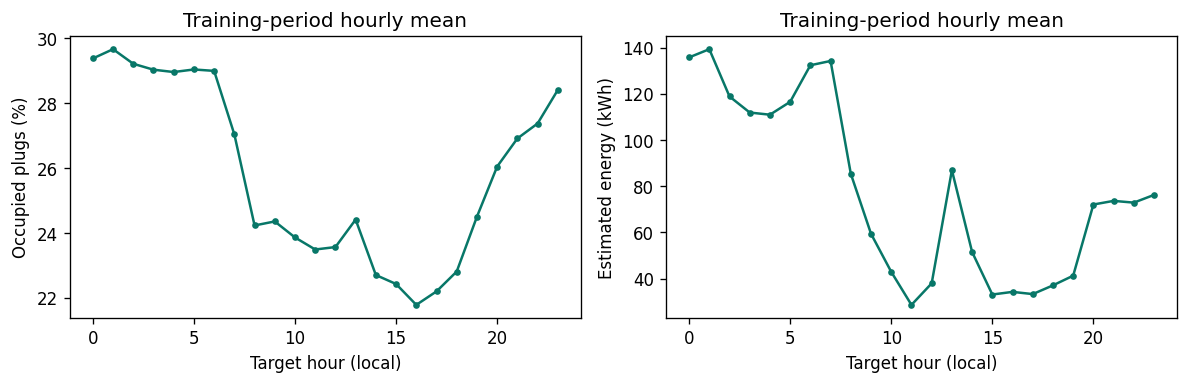

In [4]:
first = HOURS[0]
jan = (pd.Timestamp("2023-01-01")-first).days * 24
feb = (pd.Timestamp("2023-02-01")-first).days * 24
val = data[(data.slot >= jan) & (data.slot < feb)]
test = data[data.slot >= feb]
train_profile = data.loc[data.slot < jan].groupby("hour")[["next_occ","next_energy"]].mean()
fig, ax = plt.subplots(1, 2, figsize=(10,3.3))
for axis, field, scale, label in zip(ax, train_profile, [100,1], ["Occupied plugs (%)","Estimated energy (kWh)"]):
    axis.plot(train_profile.index, train_profile[field]*scale, marker=".",color="#087768")
    axis.set(xlabel="Target hour (local)",ylabel=label,title="Training-period hourly mean")
fig.tight_layout()
plt.show()

## 4 · Demand prediction and monitoring agents
Fit separate regressors for occupancy and energy. Persistence repeats the latest complete hour. The daily baseline uses yesterday’s corresponding hour, falling back to persistence. Compare two histogram gradient boosting models with identical settings: hourly inputs versus hourly plus the three within-hour signals. Boosting successively fits trees to correct residual errors.

The monitor records shadow predictions for every candidate and picks the lowest-MAE method separately per target using the previous seven days of available errors. February outcomes can influence only later days’ choices. This changes method selection, without daily weight retraining. Occupancy is bounded to [0,1] and energy to nonnegative values.

In [5]:
choices, scores, agent, predictions = {}, [], [], {}
for col, target in TARGETS.items():
    history = None
    for split, cutoff, frame in [("January",jan,val),("February",feb,test)]:
        train = data.slot < cutoff
        preds = {"persistence":frame[col].to_numpy(),
                 "previous_day":frame[f"{col}_23"].fillna(frame[col]).to_numpy()}
        for method, features in [("hourly",BASE+LAGS),("enhanced",BASE+LAGS+LAST)]:
            model = HistGradientBoostingRegressor(max_iter=100,max_leaf_nodes=23,
                        learning_rate=.09,early_stopping=False,random_state=42)
            with threadpool_limits(limits=4):
                model.fit(data.loc[train,features],data.loc[train,target])
                preds[method] = model.predict(frame[features]).clip(0,1 if col=="occ" else None)
    
        errors = pd.DataFrame({k:np.abs(v-frame[target].to_numpy()) for k,v in preds.items()},
                              index=(frame.slot.to_numpy()//24).astype(int))
        if split=="January":
            choices[col] = errors.mean().idxmin()
            history = errors
        else:
            history = pd.concat([history,errors])
            selected = np.empty(len(frame))
            for day in np.unique(errors.index):
                past = history[(history.index>=day-7)&(history.index<day)]
                method = past.mean().idxmin() if len(past) else choices[col]
                mask = errors.index==day
                selected[mask]=preds[method][mask]
                agent.append((str((first+pd.Timedelta(days=int(day))).date()),col,method,len(past)))
            preds["daily_selector"]=selected
            predictions[col]=selected
        for method,v in preds.items():
            scores.append((split,col,method,len(frame),mean_absolute_error(frame[target],v),
                           root_mean_squared_error(frame[target],v),r2_score(frame[target],v)))
        pd.DataFrame(scores,columns=["month","target","method","rows","MAE","RMSE","R2"]).to_csv(OUT/"scores.csv",index=False)
pd.DataFrame(agent,columns=["date","target","method","past_rows"]).to_csv(OUT/"agent.csv",index=False)

### Score the forecasts
MAE gives a typical absolute miss; RMSE gives more weight to large errors. R² compares squared error with predicting the test mean. Occupancy errors below are percentage points, energy errors are kWh. The matched hourly and enhanced models isolate the incremental value of the five-minute features.

target         method    MAE    RMSE    R2
   occ    persistence  2.830   6.610 0.938
   occ   previous_day  9.985  16.733 0.603
   occ         hourly  2.837   5.527 0.957
   occ       enhanced  2.313   4.760 0.968
   occ daily_selector  2.313   4.760 0.968
energy    persistence 17.558 162.701 0.886
energy   previous_day 19.437 106.305 0.951
energy         hourly 13.451  95.546 0.961
energy       enhanced 11.780  88.086 0.967
energy daily_selector 11.780  88.086 0.967


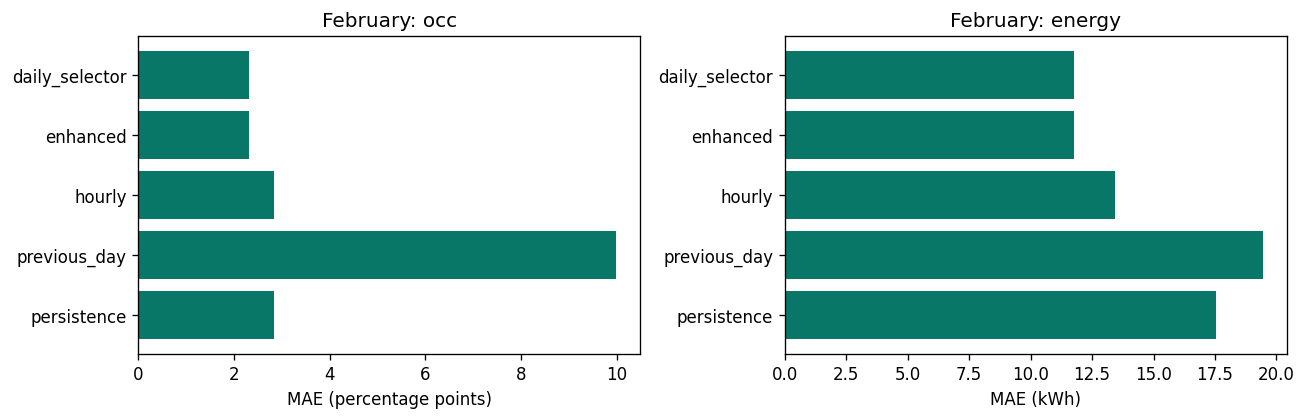

In [6]:
scores_table = pd.read_csv(OUT/"scores.csv")
feb_scores = scores_table[scores_table.month=="February"].copy()
feb_scores.loc[feb_scores.target=="occ",["MAE","RMSE"]] *= 100
print(feb_scores[["target","method","MAE","RMSE","R2"]].round(3).to_string(index=False))
fig, axes = plt.subplots(1,2,figsize=(11,3.6))
for axis, (target, group) in zip(axes, feb_scores.groupby("target",sort=False)):
    axis.barh(group.method,group.MAE,color="#087768")
    axis.set(xlabel="MAE (percentage points)" if target=="occ" else "MAE (kWh)",title="February: "+target)
fig.tight_layout()
plt.show()

## 5 · Tariff pricing agent
Quote once per station per clock hour. The base price is ₹15/kWh up to and including 60% forecast occupancy. Each successive 10-percentage-point band costs ₹1 more. Exactly 70%, 80% and 90% belong to the lower band. Actual occupancy is used only after the fact to check whether the forecast selected the intended band.

In [7]:
def quote(occupancy):
    values = np.asarray(occupancy)
    if not np.issubdtype(values.dtype, np.floating):
        values = values.astype(float)
    if not np.isfinite(values).all() or (values < 0).any() or (values > 1).any():
        raise ValueError("Occupancy must be a finite fraction between zero and one.")
    thresholds = np.array([.6,.7,.8,.9],dtype=values.dtype)
    return 15 + np.searchsorted(thresholds, values, side="left")

assert quote([0,.6,.60001,.7,.70001,.8,.80001,.9,.90001,1]).tolist()==[15,15,16,16,17,17,18,18,19,19]
replay = pd.DataFrame({"site":test.site.astype(int),"time":first+pd.to_timedelta(test.slot,unit="h"),
                       "forecast_occ":predictions["occ"],"observed_occ":test.next_occ,
                       "forecast_kwh":predictions["energy"],"estimated_kwh":test.next_energy.astype(float),
                       "price":quote(predictions["occ"]),"reference_band":quote(test.next_occ)})
assert not replay.duplicated(["site","time"]).any()
bands = pd.crosstab(replay.reference_band,replay.price).reindex(index=range(15,20),columns=range(15,20),fill_value=0)
bands.to_csv(OUT/"tariff_confusion.csv")
mix = replay.groupby("price").agg(hours=("price","size"),energy_kwh=("estimated_kwh","sum"))
mix.to_csv(OUT/"tariff_mix.csv")
print(mix.round(1).to_string())
print(f"Forecast and observed bands agree in {(replay.price==replay.reference_band).mean():.2%} of eligible hours.")
print(replay.head(3).round(3).to_string(index=False))

        hours  energy_kwh
price                    
15     554808  33446435.2
16      29556   7146493.4
17      13398   5253566.8
18       7403   3184526.1
19      28650    818218.5
Forecast and observed bands agree in 96.99% of eligible hours.
 site                time  forecast_occ  observed_occ  forecast_kwh  estimated_kwh  price  reference_band
 1001 2023-02-04 16:00:00         0.367         0.242         7.410          4.083     15              15
 1001 2023-02-04 17:00:00         0.267         0.208         6.704          4.667     15              15
 1001 2023-02-04 18:00:00         0.255         0.862        10.454          5.250     15              18


## 6 · Business replay and sensitivity
Compare the same station-hours with a flat ₹15/kWh. For baseline energy Q and quoted price P, assumed energy after the change is Q × (P/15)^e. The response exponent e is a scenario assumption about how strongly demand falls as prices rise. At e = 0 energy is unchanged; at −1 gross revenue is unchanged mathematically. Stronger response can produce a loss.

Flat revenue is Σ15Q; policy revenue is ΣP × adjusted energy. The replay uses dataset-estimated kWh and the forward view uses forecast kWh. This evaluates gross revenue only. It does not measure real customer response, profit, waiting time or transfers between sites.

            basis  elasticity     flat_INR   policy_INR  gain_pct
historical replay         0.0 7.477386e+08 7.782187e+08     4.076
historical replay        -0.5 7.477386e+08 7.624425e+08     1.966
historical replay        -1.0 7.477386e+08 7.477386e+08     0.000
historical replay        -1.5 7.477386e+08 7.340240e+08    -1.834
 forward estimate         0.0 7.270665e+08 7.564886e+08     4.047
 forward estimate        -0.5 7.270665e+08 7.412584e+08     1.952
 forward estimate        -1.0 7.270665e+08 7.270665e+08    -0.000
 forward estimate        -1.5 7.270665e+08 7.138321e+08    -1.820


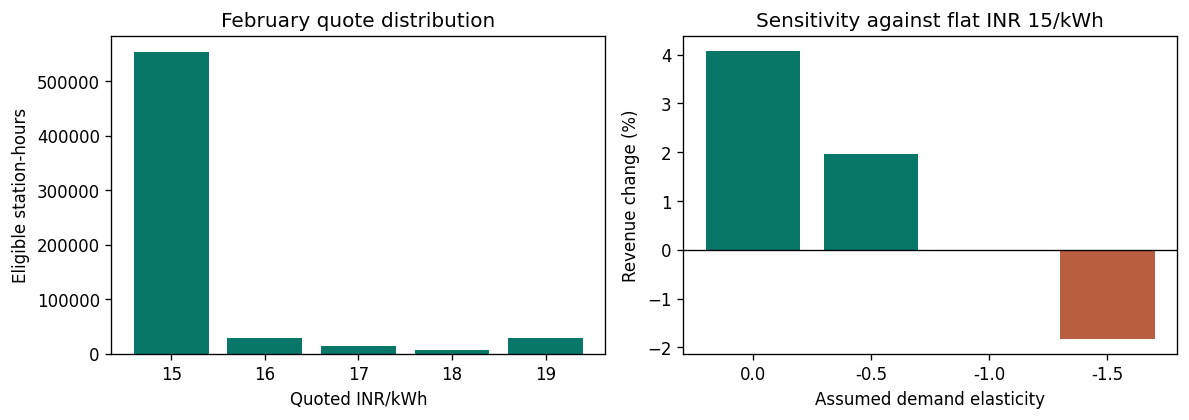

In [8]:
scenarios = []
for basis, field in [("historical replay","estimated_kwh"),("forward estimate","forecast_kwh")]:
    q = replay[field].to_numpy()
    p = replay.price.to_numpy()
    baseline = 15*q.sum()
    for elasticity in [0,-.5,-1,-1.5]:
        volume = q*(p/15)**elasticity
        gross = np.sum(p*volume)
        scenarios.append((basis,elasticity,baseline,gross,100*(gross/baseline-1)))
business = pd.DataFrame(scenarios,columns=["basis","elasticity","flat_INR","policy_INR","gain_pct"])
business.to_csv(OUT/"revenue.csv",index=False)
replay.to_csv(OUT/"holdout.csv.gz",index=False,float_format="%.8g")
assert np.allclose(business.loc[business.elasticity==-1,"gain_pct"],0,atol=1e-8)
print(business.round(3).to_string(index=False))
fig, ax = plt.subplots(1,2,figsize=(10,3.6))
ax[0].bar(mix.index,mix.hours,color="#087768")
ax[0].set(xticks=list(range(15,20)),xlabel="Quoted INR/kWh",ylabel="Eligible station-hours",title="February quote distribution")
b = business[business.basis=="historical replay"]
ax[1].bar([str(e) for e in b.elasticity],b.gain_pct,color=["#087768" if x>=0 else "#ba5e40" for x in b.gain_pct])
ax[1].axhline(0,color="black",lw=.8)
ax[1].set(xlabel="Assumed demand elasticity",ylabel="Revenue change (%)",title="Sensitivity against flat INR 15/kWh")
fig.tight_layout()
plt.show()

## 7 · Interpret the result
The forecast errors are measured on previously unseen hours at stations with valid readings. Missing coverage limits generalization to other hours and sites. More stations broaden the evidence; they do not guarantee greater accuracy. Test the pricing policy as a business hypothesis: a ₹17 quote breaks even on gross revenue if at least 15/17 = 88.24% of the original kWh are still sold. Checking real driver response requires an operator pilot with a flat-price comparison. No prices were sent to stations.

### Findings from this run

- All 1,682 station files were processed. 1,633 stations supplied 633,815 valid February cases, covering 56.1% of potential station-hours.
- Adding five-minute signals reduced February occupancy MAE from 2.84 to 2.31 percentage points and energy MAE from 13.45 to 11.78 kWh. The daily monitor selected enhanced boosting on all 28 days for both targets.
- The pricing agent recommended a premium in 12.5% of scored hours. Forecast and reference tariff bands matched in 97.0% of hours.
- Compared with flat ₹15/kWh, gross revenue changed by +4.08% with unchanged energy, +1.97% with elasticity −0.5, and -1.83% with elasticity −1.5. Under unchanged demand a nonnegative premium mechanically increases gross revenue whenever energy is sold at a premium. Customer acceptance remains unknown.
- February was held out of model fitting. Because this period had already been examined during project development, the pricing replay is retrospective. An independent later period or a controlled pilot would be needed to confirm policy performance.